# 05.1 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/01-ensembles/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from math import comb

def majority(n, p):
    """Probability that more than half of n independent voters (each right with prob p) are right."""
    return sum(comb(n, k) * p**k * (1 - p)**(n - k) for k in range(n // 2 + 1, n + 1))

## Exercise 1

At least two of three right: $k = 2$ or $k = 3$.

- $k=2$: $\binom{3}{2} \times 0.7^2 \times 0.3 = 3 \times 0.49 \times 0.3 = 0.441$
- $k=3$: $0.7^3 = 0.343$

Sum: **0.784**. Three 70% voters make a 78% committee.

In [2]:
print(f"{majority(3, 0.7):.3f}")

0.784


## Exercise 2

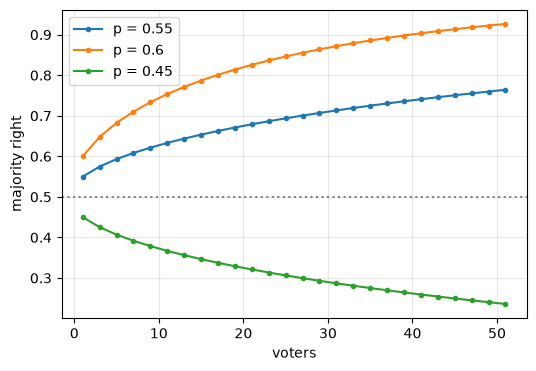

p=0.45: 1 voter 45.0%, 51 voters 23.6%


In [3]:
ns = list(range(1, 52, 2))
plt.figure(figsize=(6, 4))
for p in [0.55, 0.6, 0.45]:
    plt.plot(ns, [majority(n, p) for n in ns], marker=".", label=f"p = {p}")
plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("voters"); plt.ylabel("majority right"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"p=0.45: 1 voter {majority(1, .45):.1%}, 51 voters {majority(51, .45):.1%}")

With $p < 0.5$ the committee gets **worse** as it grows, heading to 0. Ensembles amplify whatever the members are: better than chance → better; worse than chance → worse. This is why every member must beat chance.

## Exercise 3

In [4]:
rng = np.random.default_rng(0)
rounds, n = 10_000, 25
mood = rng.random((rounds, 1)) < 0.6
own = rng.random((rounds, n)) < 0.6
copies = rng.random((rounds, n)) < 0.8
correlated = np.where(copies, mood, own)

print(f"independent: {((own.sum(1)) > 12).mean():.1%}")
print(f"correlated:  {((correlated.sum(1)) > 12).mean():.1%}")

independent: 84.9%
correlated:  60.2%


Correlation drags the committee almost back down to a single voter's 60%. When most voters copy the same opinion, the majority simply *is* that opinion.

## Exercise 4

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51))
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
members = {"logistic regression": logreg, "KNN (k=51)": knn, "tree (depth 3)": tree}

from sklearn.ensemble import VotingClassifier
est = list(zip(["lr", "knn", "tree"], members.values()))

def cv_score(model, scoring):
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scoring).mean()

print(f"hard vote           accuracy {cv_score(VotingClassifier(est, voting='hard'), 'accuracy'):.3f}")
soft = VotingClassifier(est, voting="soft")
print(f"soft vote           accuracy {cv_score(soft, 'accuracy'):.3f}   AUC {cv_score(soft, 'roc_auc'):.3f}")
weighted = VotingClassifier(est, voting="soft", weights=[2, 1, 1])
print(f"soft, weights 2-1-1 accuracy {cv_score(weighted, 'accuracy'):.3f}   AUC {cv_score(weighted, 'roc_auc'):.3f}")

hard vote           accuracy 0.679

soft vote           accuracy 0.679   AUC 0.744
soft, weights 2-1-1 accuracy 0.681   AUC 0.743


The three options land within about a point of each other. Soft voting is usually the safer default because it keeps confidence information; weighting the strongest member helps only a little when the members already agree on most customers. Read your own numbers above and decide which one you would ship, and why.